In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid")
os.makedirs("data", exist_ok=True)

## 1. Generate a small dataset (5 CSV files with built-in data quality problems)

In [2]:
rng = np.random.default_rng(42)

# ---- zones.csv (Z05 capacity deliberately too low -> capacity mismatch)
zones = pd.DataFrame({
    "zone_id":   [f"Z{i:02d}" for i in range(1, 9)],
    "location":  ["Central Market", "City Mall", "Tech Park", "Railway Station",
                  "Old Town", "Hospital Road", "University", "Riverside"],
    "capacity":  [20, 30, 40, 25, 3, 15, 30, 12],
    "zone_type": ["Commercial", "Mall", "Office", "Transit",
                  "Residential", "Commercial", "Office", "Residential"]})

# ---- calendar.csv and weather.csv (30 days)
dates = pd.date_range("2026-09-01", periods=30)
events = {"2026-09-12": "Concert", "2026-09-19": "Festival", "2026-09-26": "Cricket Match"}
calendar = pd.DataFrame({"date": dates})
calendar["weekday"] = calendar["date"].dt.day_name()
calendar["holiday"] = calendar["date"].isin(pd.to_datetime(["2026-09-07", "2026-09-21"])).astype(int)
calendar["event"] = calendar["date"].dt.strftime("%Y-%m-%d").map(events).fillna("No Event")

rainy = rng.random(30) < 0.3
weather = pd.DataFrame({"date": dates,
                        "rain_mm": np.where(rainy, rng.exponential(8, 30), 0).round(1),
                        "temperature": rng.normal(30, 3, 30).round(1)})

# ---- parking_sessions.csv and payments.csv
mean_hour = {"Office": 9, "Mall": 17, "Commercial": 12, "Transit": 8, "Residential": 19}
mean_dur  = {"Office": 480, "Mall": 120, "Commercial": 90, "Transit": 240, "Residential": 360}
rate      = {"Office": 20, "Mall": 40, "Commercial": 30, "Transit": 25, "Residential": 10}
base_w = np.array([0.14, 0.20, 0.18, 0.15, 0.06, 0.10, 0.12, 0.05])

rows = []
for i, d in enumerate(dates):
    mult = 1.0
    mult *= 1.1 if d.weekday() >= 5 else 1.0
    mult *= 1.2 if calendar.loc[i, "holiday"] else 1.0
    mult *= 1.4 if calendar.loc[i, "event"] != "No Event" else 1.0
    mult *= 0.8 if weather.loc[i, "rain_mm"] > 1 else 1.0
    w = base_w.copy()
    if calendar.loc[i, "event"] != "No Event":
        w[[1, 7]] *= 2.5            # events push demand to the mall and riverside
    w /= w.sum()
    for _ in range(int(rng.normal(100, 8) * mult)):
        z = rng.choice(len(zones), p=w)
        t = zones.loc[z, "zone_type"]
        hr = np.clip(rng.normal(mean_hour[t], 2.5), 6, 22)
        entry = d + pd.Timedelta(hours=float(hr))
        dur = min(rng.gamma(4, mean_dur[t] / 4) * (1.15 if weather.loc[i, "rain_mm"] > 1 else 1), 720)
        rows.append([zones.loc[z, "zone_id"], entry, entry + pd.Timedelta(minutes=dur),
                     round(dur, 1), round(dur / 60 * rate[t])])

sessions = pd.DataFrame(rows, columns=["zone", "entry", "exit", "duration", "fee"])
sessions.insert(0, "session_id", [f"S{i:05d}" for i in range(len(sessions))])

payments = pd.DataFrame({"session_id": sessions["session_id"],
                         "payment_mode": rng.choice(["Card", "UPI", "Cash", "App Wallet"], len(sessions)),
                         "amount": sessions["fee"]})

# ---- inject data quality problems
bad = rng.choice(sessions.index, 60, replace=False)                      # negative durations
sessions.loc[bad[:20], "exit"] = sessions.loc[bad[:20], "entry"] - pd.Timedelta(minutes=45)
sessions.loc[bad[:20], "duration"] = -45
sessions.loc[bad[20:], ["exit", "duration"]] = np.nan                     # missing exit times
messy = rng.choice(sessions.index, 300, replace=False)                    # inconsistent zone labels
sessions.loc[messy, "zone"] = [rng.choice(["z%d", " Z%02d", "Zone-%d"]) % int(z[1:])
                               for z in sessions.loc[messy, "zone"]]
sessions = pd.concat([sessions, sessions.sample(40, random_state=1)], ignore_index=True)  # duplicates

sessions.to_csv("data/parking_sessions.csv", index=False)
zones.to_csv("data/zones.csv", index=False)
payments.to_csv("data/payments.csv", index=False)
calendar.to_csv("data/calendar.csv", index=False)
weather.to_csv("data/weather.csv", index=False)
print("Files created:", os.listdir("data"))

Files created: ['calendar.csv', 'parking_sessions.csv', 'payments.csv', 'weather.csv', 'zones.csv']


## 2. Load and understand the data

In [3]:
sessions = pd.read_csv("data/parking_sessions.csv", parse_dates=["entry", "exit"])
zones    = pd.read_csv("data/zones.csv")
payments = pd.read_csv("data/payments.csv")
calendar = pd.read_csv("data/calendar.csv", parse_dates=["date"])
weather  = pd.read_csv("data/weather.csv", parse_dates=["date"])

for name, d in [("sessions", sessions), ("zones", zones), ("payments", payments),
                ("calendar", calendar), ("weather", weather)]:
    print(f"--- {name}: {d.shape}")
    display(d.head(3))

--- sessions: (3092, 6)

,session_id,zone,entry,exit,duration,fee
0,S00000,Z05,2026-09-01 20:39:48.465980755,2026-09-02 01:53:07.464247447,313.3,52
1,S00001,Z04,2026-09-01 06:00:00.000000000,2026-09-01 07:32:06.314178866,92.1,38
2,S00002,Z08,2026-09-01 19:59:57.968040510,2026-09-01 23:17:13.387467816,197.3,33


--- zones: (8, 4)


,zone_id,location,capacity,zone_type
0,Z01,Central Market,20,Commercial
1,Z02,City Mall,30,Mall
2,Z03,Tech Park,40,Office


--- payments: (3052, 3)


,session_id,payment_mode,amount
0,S00000,Cash,52
1,S00001,Cash,38
2,S00002,Cash,33


--- calendar: (30, 4)


,date,weekday,holiday,event
0,2026-09-01,Tuesday,0,No Event
1,2026-09-02,Wednesday,0,No Event
2,2026-09-03,Thursday,0,No Event


--- weather: (30, 3)


,date,rain_mm,temperature
0,2026-09-01,0.0,27.4
1,2026-09-02,0.0,32.9
2,2026-09-03,0.0,25.0


### Data types, missing values, duplicates and unusual values

In [4]:
sessions.info()
print("\nMissing values:\n", sessions.isna().sum())
print("\nDuplicate rows:", sessions.duplicated().sum())
print("Negative durations:", (sessions["duration"] < 0).sum())
print("\nZone labels found:", sorted(sessions["zone"].unique()))
display(sessions.describe())

<class 'pandas.DataFrame'>
RangeIndex: 3092 entries, 0 to 3091
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   session_id  3092 non-null   str           
 1   zone        3092 non-null   str           
 2   entry       3092 non-null   datetime64[ns]
 3   exit        3051 non-null   datetime64[ns]
 4   duration    3051 non-null   float64       
 5   fee         3092 non-null   int64         
dtypes: datetime64[ns](2), float64(1), int64(1), str(2)
memory usage: 145.1 KB

Missing values:
 session_id     0
zone           0
entry          0
exit          41
duration      41
fee            0
dtype: int64

Duplicate rows: 40
Negative durations: 20

Zone labels found: [' Z01', ' Z02', ' Z03', ' Z04', ' Z05', ' Z06', ' Z07', ' Z08', 'Z01', 'Z02', 'Z03', 'Z04', 'Z05', 'Z06', 'Z07', 'Z08', 'Zone-1', 'Zone-2', 'Zone-3', 'Zone-4', 'Zone-5', 'Zone-6', 'Zone-7', 'Zone-8', 'z1', 'z2', 'z3', 'z4', 'z5', 'z6', 'z7', 'z8

,entry,exit,duration,fee
count,3092,3051,3051.000000,3092.000000
mean,2026-09-16 01:05:03.002791424,2026-09-16 05:57:18.193929216,257.355326,95.516171
min,2026-09-01 06:00:00,2026-09-01 07:32:06.314178866,-45.000000,4.000000
25%,2026-09-08 16:57:03.668752896,2026-09-08 22:03:13.902522880,98.400000,47.000000
50%,2026-09-16 06:00:00,2026-09-16 11:19:23.802423552,185.300000,78.000000
75%,2026-09-22 20:32:12.837347840,2026-09-23 07:52:47.926449152,376.000000,128.000000
max,2026-09-30 22:00:00,2026-10-01 06:48:10.171439293,720.000000,311.000000
std,NaN,NaN,202.070710,62.126363


**Problems found:** missing exit times, duplicate sessions, inconsistent zone labels (`z3`, ` Z03`, `Zone-3`), negative durations. Capacity mismatch is checked after cleaning.

## 3. Clean the data

In [5]:
s = sessions.drop_duplicates().copy()                                   # 1. duplicates

num = s["zone"].str.extract(r"(\d+)")[0].astype(int)                    # 2. zone labels -> Z01..Z08
s["zone_id"] = "Z" + num.astype(str).str.zfill(2)
s = s.drop(columns="zone")

s = s[~(s["exit"] < s["entry"])].copy()                                 # 3. negative durations -> remove

s["duration"] = (s["exit"] - s["entry"]).dt.total_seconds() / 60       # 4. missing exit -> zone median
med = s.groupby("zone_id")["duration"].transform("median")
miss = s["exit"].isna()
s.loc[miss, "duration"] = med[miss]
s.loc[miss, "exit"] = s.loc[miss, "entry"] + pd.to_timedelta(med[miss], unit="m")

s["date"] = s["entry"].dt.normalize()
print("Rows before:", len(sessions), "| after:", len(s))
print("Remaining missing:", s.isna().sum().sum(), "| zones:", sorted(s["zone_id"].unique()))

Rows before: 3092 | after: 3032
Remaining missing: 0 | zones: ['Z01', 'Z02', 'Z03', 'Z04', 'Z05', 'Z06', 'Z07', 'Z08']


### Capacity mismatch check
Count how many cars are parked in each zone every hour and compare with the listed capacity.

In [6]:
hours = pd.date_range("2026-09-01", "2026-09-30 23:00", freq="h")
rows = [(r.zone_id, h) for r in s.itertuples()
        for h in pd.date_range(r.entry.floor("h"), r.exit.floor("h"), freq="h")]
cnt = pd.DataFrame(rows, columns=["zone_id", "hour"]).value_counts().rename("vehicles").reset_index()

grid = pd.MultiIndex.from_product([zones["zone_id"], hours], names=["zone_id", "hour"]).to_frame(index=False)
zh = grid.merge(cnt, how="left").fillna({"vehicles": 0})      # zone-hour table

peak = zh.groupby("zone_id")["vehicles"].max()
check = zones.set_index("zone_id")[["capacity"]].assign(peak_vehicles=peak)
check["mismatch"] = check["peak_vehicles"] > check["capacity"]
display(check)

# fix: capacity cannot be lower than the peak ever observed
zones["capacity"] = np.maximum(zones["capacity"], zones["zone_id"].map(peak)).astype(int)

,capacity,peak_vehicles,mismatch
zone_id,,,
Z01,20,13.0,False
Z02,30,29.0,False
Z03,40,21.0,False
Z04,25,17.0,False
Z05,3,8.0,True
Z06,15,8.0,False
Z07,30,17.0,False
Z08,12,11.0,False


## 4. Combine the data
Session level table = sessions + zones + payments + calendar + weather.  
Zone-hour table = hourly vehicle counts per zone + zones + calendar + weather.

In [7]:
pay = payments.drop_duplicates("session_id")
df = (s.merge(zones, on="zone_id")
        .merge(pay, on="session_id", how="left")
        .merge(calendar, on="date", how="left")
        .merge(weather, on="date", how="left"))

zh = (zh.merge(zones, on="zone_id"))
zh["date"] = zh["hour"].dt.normalize()
zh = zh.merge(calendar, on="date").merge(weather, on="date")
zh["occupancy_rate"] = zh["vehicles"] / zh["capacity"]
zh["hour_of_day"] = zh["hour"].dt.hour

print("Session table:", df.shape, "| Zone-hour table:", zh.shape)
display(df.head())

Session table: (3032, 17) | Zone-hour table: (5760, 14)


,session_id,entry,exit,duration,fee,zone_id,date,location,capacity,zone_type,payment_mode,amount,weekday,holiday,event,rain_mm,temperature
0,S00000,2026-09-01 20:39:48.465980755,2026-09-02 01:53:07.464247447,313.316638,52,Z05,2026-09-01,Old Town,8,Residential,Cash,52,Tuesday,0,No Event,0.0,27.4
1,S00001,2026-09-01 06:00:00.000000000,2026-09-01 07:32:06.314178866,92.105236,38,Z04,2026-09-01,Railway Station,25,Transit,Cash,38,Tuesday,0,No Event,0.0,27.4
2,S00002,2026-09-01 19:59:57.968040510,2026-09-01 23:17:13.387467816,197.256990,33,Z08,2026-09-01,Riverside,12,Residential,Cash,33,Tuesday,0,No Event,0.0,27.4
3,S00003,2026-09-01 18:06:33.624260447,2026-09-02 02:00:40.664144893,474.117331,79,Z08,2026-09-01,Riverside,12,Residential,Card,79,Tuesday,0,No Event,0.0,27.4
4,S00004,2026-09-01 14:37:29.801505804,2026-09-01 16:09:08.852767340,91.650854,61,Z02,2026-09-01,City Mall,30,Mall,App Wallet,61,Tuesday,0,No Event,0.0,27.4


## 5. Descriptive analysis

,duration_hours,fee,rain_mm,temperature
count,3032.000000,3032.000000,3032.000000,3032.000000
mean,4.320516,95.548813,0.918404,29.563325
std,3.342838,62.118300,2.239181,2.113580
min,0.139739,4.000000,0.000000,25.000000
25%,1.664523,47.000000,0.000000,28.600000
50%,3.134302,78.000000,0.000000,29.100000
75%,6.305512,128.250000,0.000000,31.500000
max,12.000000,311.000000,10.800000,32.900000


payment_mode
Card          774
App Wallet    757
UPI           754
Cash          747
Name: count, dtype: int64


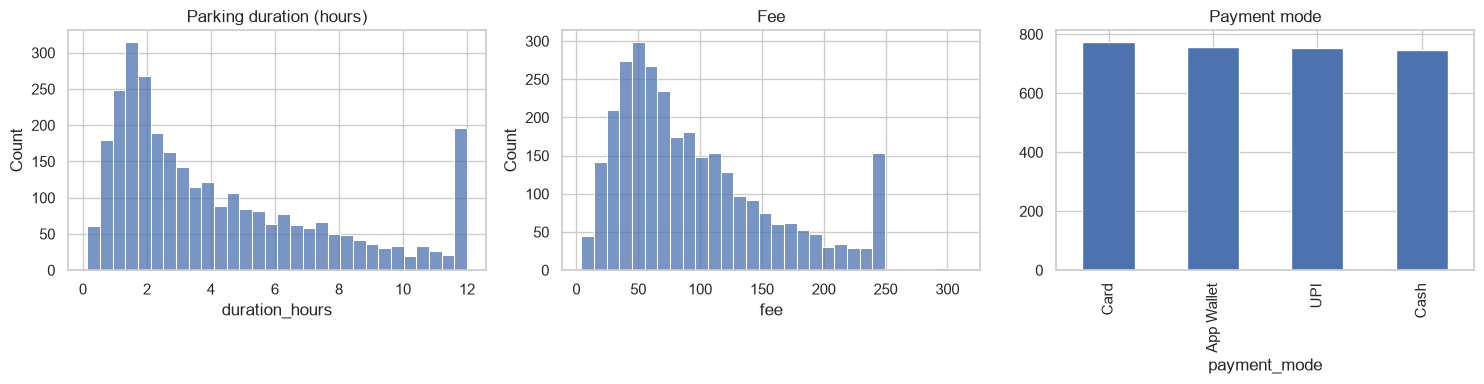

In [8]:
df["duration_hours"] = df["duration"] / 60
display(df[["duration_hours", "fee", "rain_mm", "temperature"]].describe())
print(df["payment_mode"].value_counts())

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df["duration_hours"], bins=30, ax=ax[0]); ax[0].set_title("Parking duration (hours)")
sns.histplot(df["fee"], bins=30, ax=ax[1]);            ax[1].set_title("Fee")
df["payment_mode"].value_counts().plot.bar(ax=ax[2]);   ax[2].set_title("Payment mode")
plt.tight_layout(); plt.show()

## 6. Analytical questions

In [9]:
# summary per zone (daytime hours 6:00-21:59)
day = zh[zh["hour_of_day"].between(6, 21)]
zone_summary = zones.set_index("zone_id").assign(
    sessions=df.groupby("zone_id").size(),
    avg_occupancy=day.groupby("zone_id")["occupancy_rate"].mean(),
    avg_duration_h=df.groupby("zone_id")["duration_hours"].mean())
zone_summary["turnover"] = zone_summary["sessions"] / zone_summary["capacity"] / 30   # sessions per space per day
display(zone_summary.sort_values("avg_occupancy", ascending=False))

,location,capacity,zone_type,sessions,avg_occupancy,avg_duration_h,turnover
zone_id,,,,,,,
Z03,Tech Park,40,Office,502,0.222135,7.789321,0.418333
Z07,University,30,Office,373,0.216389,7.566932,0.414444
Z04,Railway Station,25,Transit,460,0.195000,4.189265,0.613333
Z05,Old Town,8,Residential,177,0.152865,5.757955,0.737500
Z02,City Mall,30,Mall,672,0.131667,2.044688,0.746667
Z01,Central Market,20,Commercial,424,0.107917,1.481464,0.706667
Z06,Hospital Road,15,Commercial,265,0.094028,1.576085,0.588889
Z08,Riverside,12,Residential,159,0.093924,6.295889,0.441667


### Q1. Which zones have the highest occupancy?

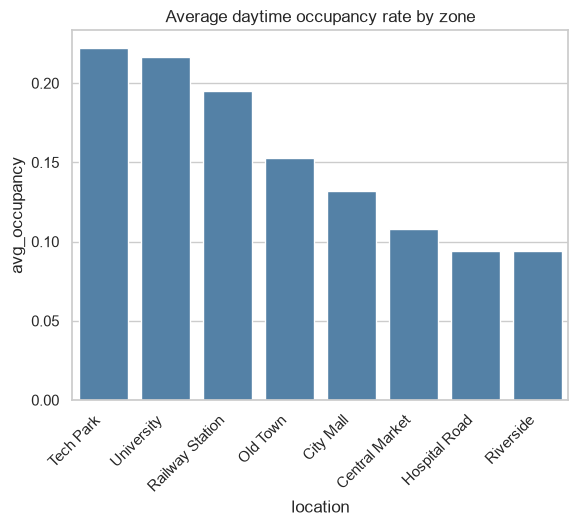

Highest: Z03 Tech Park | Lowest: Z08 Riverside


In [10]:
zs = zone_summary.sort_values("avg_occupancy", ascending=False)
sns.barplot(data=zs, x="location", y="avg_occupancy", color="steelblue")
plt.xticks(rotation=45, ha="right"); plt.title("Average daytime occupancy rate by zone"); plt.show()
print("Highest:", zs.index[0], zs["location"].iloc[0], "| Lowest:", zs.index[-1], zs["location"].iloc[-1])

### Q2. When are the peak parking periods?

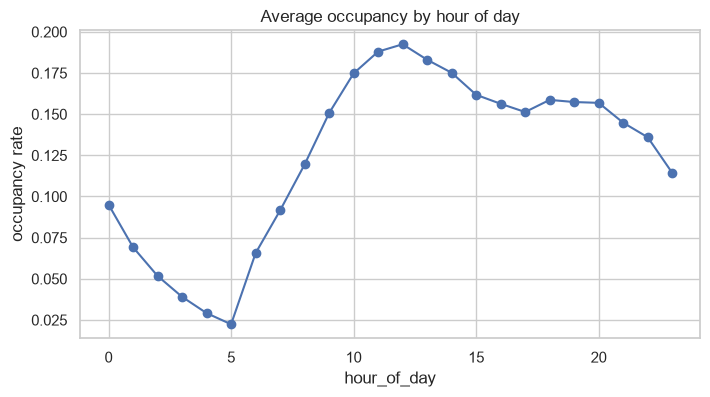

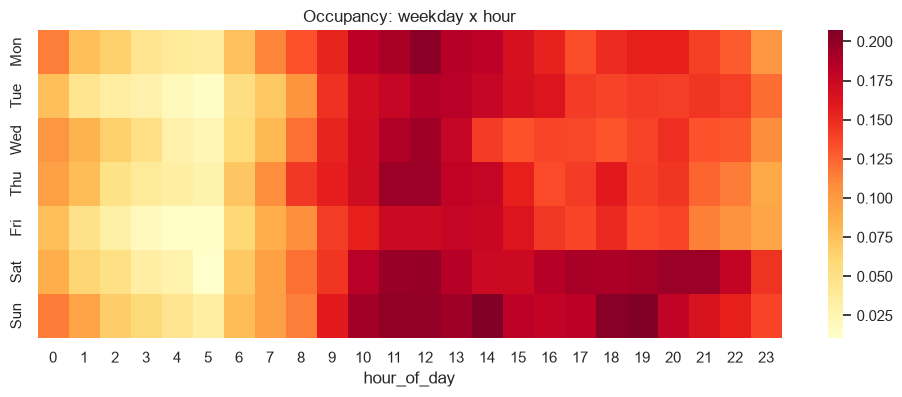

Peak hour: 12 :00


In [11]:
hourly = zh.groupby("hour_of_day")["occupancy_rate"].mean()
hourly.plot(marker="o", figsize=(8, 4)); plt.title("Average occupancy by hour of day"); plt.ylabel("occupancy rate"); plt.show()

zh["weekday_num"] = zh["hour"].dt.weekday
heat = zh.pivot_table(index="weekday_num", columns="hour_of_day", values="occupancy_rate")
heat.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
plt.figure(figsize=(12, 4)); sns.heatmap(heat, cmap="YlOrRd"); plt.title("Occupancy: weekday x hour"); plt.show()
print("Peak hour:", hourly.idxmax(), ":00")

### Q3. Which zones have low turnover?

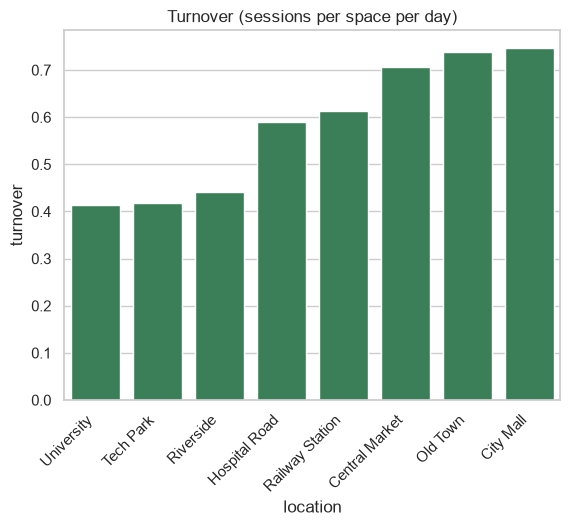

Lowest turnover: ['University', 'Tech Park', 'Riverside']


In [12]:
zt = zone_summary.sort_values("turnover")
sns.barplot(data=zt, x="location", y="turnover", color="seagreen")
plt.xticks(rotation=45, ha="right"); plt.title("Turnover (sessions per space per day)"); plt.show()
print("Lowest turnover:", list(zt["location"].head(3)))

### Q4. How do events affect occupancy?

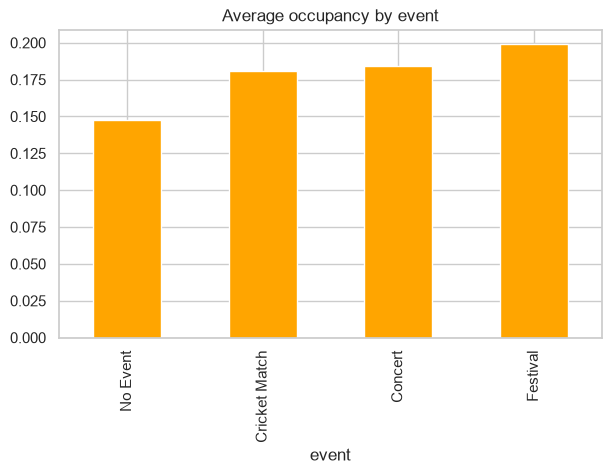

event_flag
no event     0.147706
event day    0.188047
Name: occupancy_rate, dtype: float64
Event days change occupancy by 27.3%


In [13]:
day = zh[zh["hour_of_day"].between(6, 21)]
ev = day.groupby("event")["occupancy_rate"].mean().sort_values()
ev.plot.bar(color="orange", figsize=(7, 4)); plt.title("Average occupancy by event"); plt.show()

flag = day.assign(event_flag=day["event"] != "No Event").groupby("event_flag")["occupancy_rate"].mean()
print(flag.rename({False: "no event", True: "event day"}))
print(f"Event days change occupancy by {(flag[True] / flag[False] - 1) * 100:.1f}%")

### Q5. Does rain change parking behaviour?

C:\Users\ANUMITHA\AppData\Local\Temp\ipykernel_21932\2340131318.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  for a in ax: a.set_xticklabels(["Dry", "Rain"])
C:\Users\ANUMITHA\AppData\Local\Temp\ipykernel_21932\2340131318.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  for a in ax: a.set_xticklabels(["Dry", "Rain"])
C:\Users\ANUMITHA\AppData\Local\Temp\ipykernel_21932\2340131318.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  for a in ax: a.set_xticklabels(["Dry", "Rain"])


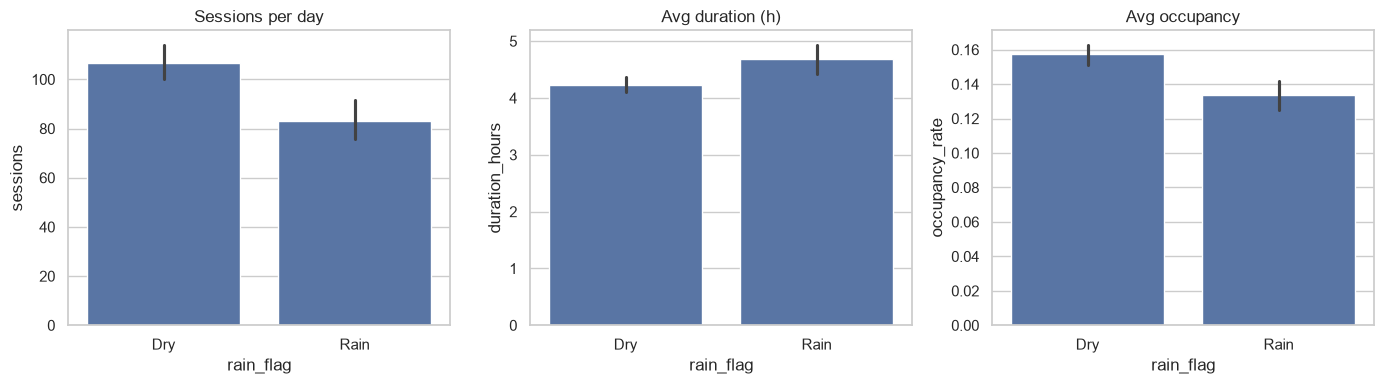

rain_flag
0    4.23
1    4.68
Name: duration_hours, dtype: float64


In [14]:
df["rain_flag"] = (df["rain_mm"] > 1).astype(int)
day = day.assign(rain_flag=(day["rain_mm"] > 1).astype(int))
per_day = df.groupby(["date", "rain_flag"]).size().reset_index(name="sessions")

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
sns.barplot(data=per_day, x="rain_flag", y="sessions", ax=ax[0]);        ax[0].set_title("Sessions per day")
sns.barplot(data=df, x="rain_flag", y="duration_hours", ax=ax[1]);        ax[1].set_title("Avg duration (h)")
sns.barplot(data=day, x="rain_flag", y="occupancy_rate", ax=ax[2]);       ax[2].set_title("Avg occupancy")
for a in ax: a.set_xticklabels(["Dry", "Rain"])
plt.tight_layout(); plt.show()
print(df.groupby("rain_flag")["duration_hours"].mean().round(2))

### Q6. How does duration vary by zone type?

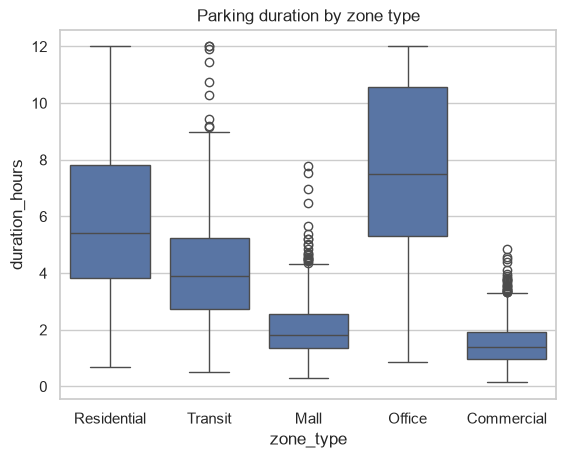

zone_type
Commercial     1.52
Mall           2.04
Transit        4.19
Residential    6.01
Office         7.69
Name: duration_hours, dtype: float64


In [15]:
sns.boxplot(data=df, x="zone_type", y="duration_hours")
plt.title("Parking duration by zone type"); plt.show()
print(df.groupby("zone_type")["duration_hours"].mean().round(2).sort_values())

### Relationships between numeric variables

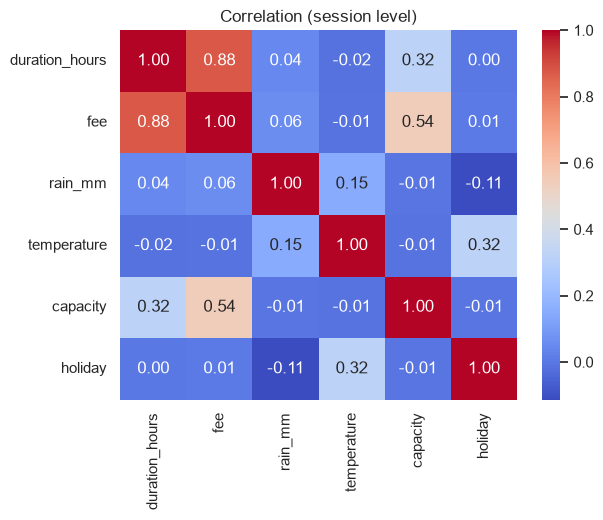

In [16]:
sns.heatmap(df[["duration_hours", "fee", "rain_mm", "temperature", "capacity", "holiday"]].corr(),
            annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation (session level)"); plt.show()

## 7. Encode, create features and select features

In [17]:
# ---- session level: new features + encoding, saved as the cleaned dataset
df["entry_hour"] = df["entry"].dt.hour
df["fee_per_hour"] = df["fee"] / df["duration_hours"]
df["is_long_stay"] = (df["duration_hours"] > 4).astype(int)
df["is_weekend"] = df["entry"].dt.weekday.isin([5, 6]).astype(int)
df["event_flag"] = (df["event"] != "No Event").astype(int)

cleaned = pd.get_dummies(df, columns=["payment_mode"], dtype=int)      # one-hot encode
cleaned.to_csv("cleaned_parking_sessions.csv", index=False)
print("Cleaned dataset saved:", cleaned.shape)

Cleaned dataset saved: (3032, 27)


In [18]:
# ---- zone-hour level features (target = occupancy_rate)
f = zh.copy()
f["is_weekend"] = (f["weekday_num"] >= 5).astype(int)
f["is_peak"] = f["hour_of_day"].isin([8, 9, 10, 17, 18, 19]).astype(int)
f["rain_flag"] = (f["rain_mm"] > 1).astype(int)
f["event_flag"] = (f["event"] != "No Event").astype(int)
f["prev_hour_occ"] = f.groupby("zone_id")["occupancy_rate"].shift(1).fillna(0)
f = pd.get_dummies(f, columns=["zone_type"], dtype=int)                # encode zone type

target = "occupancy_rate"
drop = ["zone_id", "hour", "date", "weekday", "event", "location", "vehicles", target]
X = f.drop(columns=drop)
y = f[target]
print("Candidate features:", list(X.columns))

Candidate features: ['capacity', 'holiday', 'rain_mm', 'temperature', 'hour_of_day', 'weekday_num', 'is_weekend', 'is_peak', 'rain_flag', 'event_flag', 'prev_hour_occ', 'zone_type_Commercial', 'zone_type_Mall', 'zone_type_Office', 'zone_type_Residential', 'zone_type_Transit']


In [19]:
# 1) correlation with target
corr = X.corrwith(y).abs().sort_values(ascending=False)
print(corr.round(3))

# 2) drop one of any pair of features that are >0.9 correlated
c = X.corr().abs()
upper = c.where(np.triu(np.ones(c.shape), k=1).astype(bool))
to_drop = [col for col in upper.columns if (upper[col] > 0.9).any()]
X2 = X.drop(columns=to_drop)
print("\nDropped (highly correlated):", to_drop)

# 3) keep the top 8 using univariate F-test
sel = SelectKBest(f_regression, k=8).fit(X2, y)
selected = list(X2.columns[sel.get_support()])
print("\nSelected features:", selected)

pd.concat([f[selected], y], axis=1).to_csv("selected_features.csv", index=False)

prev_hour_occ            0.914
hour_of_day              0.209
zone_type_Commercial     0.202
zone_type_Residential    0.155
is_peak                  0.098
zone_type_Office         0.089
zone_type_Mall           0.067
is_weekend               0.059
event_flag               0.056
rain_flag                0.047
rain_mm                  0.037
weekday_num              0.035
holiday                  0.019
temperature              0.015
capacity                 0.014
zone_type_Transit        0.013
dtype: float64

Dropped (highly correlated): []



Selected features:

 ['hour_of_day', 'is_weekend', 'is_peak', 'prev_hour_occ', 'zone_type_Commercial', 'zone_type_Mall', 'zone_type_Office', 'zone_type_Residential']


Components needed for 90% variance: 10 of 16


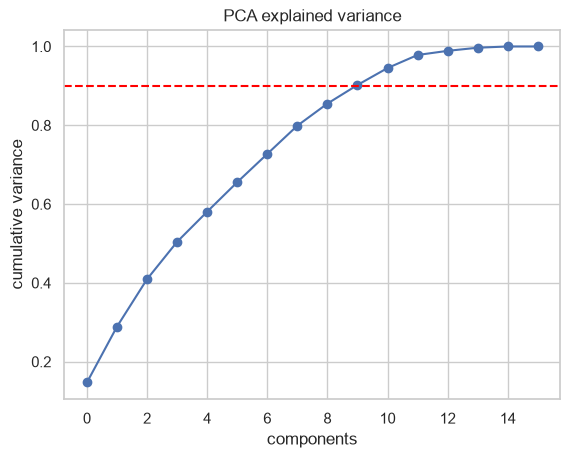

In [20]:
# Dimensionality reduction (PCA) - keep components explaining 90% variance
Xs = StandardScaler().fit_transform(X2)
pca = PCA(n_components=0.90).fit(Xs)
print("Components needed for 90% variance:", pca.n_components_, "of", X2.shape[1])
plt.plot(np.cumsum(PCA().fit(Xs).explained_variance_ratio_), marker="o")
plt.axhline(0.9, color="red", ls="--"); plt.xlabel("components"); plt.ylabel("cumulative variance")
plt.title("PCA explained variance"); plt.show()

## Summary
Evidence produced: `cleaned_parking_sessions.csv` (cleaned dataset), key visualizations above, engineered features (`duration_hours`, `fee_per_hour`, `is_long_stay`, `is_weekend`, `is_peak`, `rain_flag`, `event_flag`, `prev_hour_occ`, `occupancy_rate`, `turnover`) and `selected_features.csv` (selected features).